# 12 — Graph Neural Networks I: Message Passing

Based on §4.1 of Bronstein, Bruna, Cohen, and Veličković, *Geometric Deep Learning: Grids, Groups, Graphs, Geodesics, and Gauges*, supplemented by William L. Hamilton, *Graph Representation Learning*, especially Chapters 5–7.

This notebook introduces message-passing neural networks (MPNNs), local aggregation, node- and graph-level representations, and the relationship between message-passing GNNs and the 1-dimensional Weisfeiler–Lehman (1-WL) colour-refinement test.

**Prerequisites:** `11_graph_theory_fundamentals.ipynb`, basic PyTorch, and the graph data model from `10_pytorch_geometric_tutorial.ipynb`.

## 1. Message passing: the basic pattern

Let $G=(V,E)$ be a graph, with node states $h_v^{(0)}$. A message-passing layer first computes messages from neighbours, aggregates them, then updates the node state:

$$
m_v^{(t)}=\operatorname{AGG}_{u\in\mathcal N(v)}
\operatorname{MSG}_t(h_v^{(t-1)},h_u^{(t-1)},e_{uv}),
$$

$$
h_v^{(t)}=\operatorname{UPD}_t(h_v^{(t-1)},m_v^{(t)}).
$$

The message and update functions may be neural networks. Aggregation is usually permutation-invariant (sum, mean, max, or an attention-weighted sum), because the neighbours have no canonical ordering. After \(t\) layers, a node can depend on nodes up to \(t\) hops away.

**Example:** sum the features of a node's neighbours, then combine that sum with its own feature.

**Non-example:** concatenate neighbour features in the arbitrary order returned by a graph library. Without a canonical ordering, this is generally sensitive to node relabeling.

## 2. A small graph with scalar node features

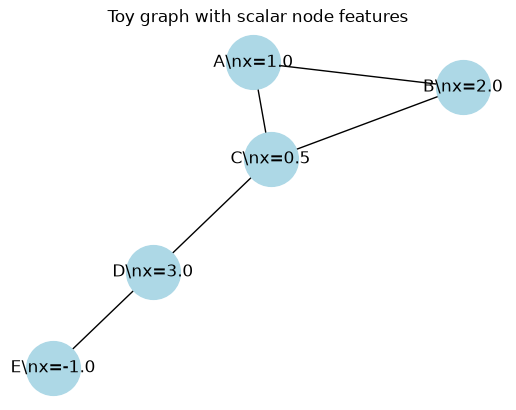

Neighbourhoods: {'A': ['B', 'C'], 'B': ['A', 'C'], 'C': ['A', 'B', 'D'], 'D': ['C', 'E'], 'E': ['D']}


In [1]:
import numpy as np
import networkx as nx
import matplotlib.pyplot as plt
import torch
from torch import nn

G = nx.Graph()
G.add_edges_from([("A", "B"), ("A", "C"), ("B", "C"), ("C", "D"), ("D", "E")])
nodes = list(G.nodes())
x = {"A": 1.0, "B": 2.0, "C": 0.5, "D": 3.0, "E": -1.0}
pos = nx.spring_layout(G, seed=7)

nx.draw_networkx(G, pos, labels={v: f"{v}\\nx={x[v]}" for v in nodes},
                 node_color="lightblue", node_size=1500)
plt.title("Toy graph with scalar node features")
plt.axis("off")
plt.show()

print("Neighbourhoods:", {v: sorted(G.neighbors(v)) for v in nodes})

## 3. One hand-built message-passing layer

Take the message from \(u\) to \(v\) to be \(h_u\), aggregate by summation, and update by adding the aggregate to the current feature:

$$
m_v=\sum_{u\in\mathcal N(v)}h_u,\qquad h'_v=h_v+m_v.
$$

This is deliberately simple: it exposes the mechanics rather than presenting a useful trained model.

In [2]:
messages = {v: {u: x[u] for u in G.neighbors(v)} for v in nodes}
aggregated = {v: sum(messages[v].values()) for v in nodes}
updated = {v: x[v] + aggregated[v] for v in nodes}

for v in nodes:
    print(f"{v}: own={x[v]}, messages={messages[v]}, "
          f"sum={aggregated[v]}, updated={updated[v]}")

# Sum aggregation does not depend on the order of neighbours.
vals = [x[u] for u in G.neighbors("C")]
assert np.isclose(sum(vals), sum(reversed(vals)))
print("Permutation-invariance check passed for sum aggregation.")

A: own=1.0, messages={'B': 2.0, 'C': 0.5}, sum=2.5, updated=3.5
B: own=2.0, messages={'A': 1.0, 'C': 0.5}, sum=1.5, updated=3.5
C: own=0.5, messages={'A': 1.0, 'B': 2.0, 'D': 3.0}, sum=6.0, updated=6.5
D: own=3.0, messages={'C': 0.5, 'E': -1.0}, sum=-0.5, updated=2.5
E: own=-1.0, messages={'D': 3.0}, sum=3.0, updated=2.0
Permutation-invariance check passed for sum aggregation.


## 4. A learnable message-passing layer

A simple parameterized layer is

$$
h_v^{(t)}=\sigma\left(
W_{\rm self}h_v^{(t-1)}
+W_{\rm nbr}\sum_{u\in\mathcal N(v)}h_u^{(t-1)}+b
\right).
$$

Weights are shared across vertices. This permits the same layer to operate on graphs with different numbers of nodes.

In [3]:
node_to_idx = {v: i for i, v in enumerate(nodes)}
X = torch.tensor([[x[v]] for v in nodes], dtype=torch.float32)
A = torch.tensor(nx.to_numpy_array(G, nodelist=nodes), dtype=torch.float32)

class SimpleMessagePassing(nn.Module):
    def __init__(self, in_features, out_features):
        super().__init__()
        self.self_linear = nn.Linear(in_features, out_features, bias=False)
        self.neighbour_linear = nn.Linear(in_features, out_features)

    def forward(self, x, adjacency):
        neighbour_sum = adjacency @ x
        return torch.relu(self.self_linear(x) + self.neighbour_linear(neighbour_sum))

torch.manual_seed(0)
layer = SimpleMessagePassing(1, 3)
H = layer(X, A)
print("Input shape:", tuple(X.shape), "Output shape:", tuple(H.shape))
print(H.detach())

Input shape: (5, 1) Output shape: (5, 3)
tensor([[0.0000, 0.3664, 0.0000],
        [0.0000, 1.2880, 0.0000],
        [0.0000, 0.0000, 1.1087],
        [0.3257, 2.5948, 0.0000],
        [0.0000, 0.0000, 1.5388]])


The dense adjacency matrix is convenient for a tiny example but inefficient for large sparse graphs. In practice, graph libraries commonly use edge lists and scatter/segment aggregation.

## 5. Node-level and graph-level predictions

A **node-level** task predicts one label or value per vertex. A **graph-level** task predicts a property of the entire graph, such as a molecular property. Graph-level models typically apply a permutation-invariant readout:

$$
h_G=\operatorname{READOUT}\{h_v^{(L)}:v\in V\}.
$$

Sum, mean, and max readouts have different properties. Sum can retain information about graph size; mean normalizes by node count; max selects coordinate-wise maxima.

In [4]:
print("Sum readout: ", H.sum(dim=0).detach().numpy())
print("Mean readout:", H.mean(dim=0).detach().numpy())
print("Max readout: ", H.max(dim=0).values.detach().numpy())

Sum readout:  [0.32569587 4.2492895  2.647451  ]
Mean readout: [0.06513917 0.8498579  0.5294902 ]
Max readout:  [0.32569587 2.5947974  1.5387732 ]


## 6. The Weisfeiler–Lehman colour-refinement test

The **1-dimensional Weisfeiler–Lehman test** (1-WL, or colour refinement) is a combinatorial procedure for comparing graph structure. Every vertex starts with a discrete colour, often the same colour for all vertices. At each round, a vertex's new colour encodes its current colour and the multiset of colours of its neighbours:

$$
c_v^{(t)}=\operatorname{HASH}\left(
c_v^{(t-1)},
\{\!\{c_u^{(t-1)}:u\in\mathcal N(v)\}\!\}
\right).
$$

The double braces denote a **multiset**: order is ignored, but multiplicity matters. In comparing two graphs, if their colour histograms differ at any round, they are non-isomorphic. If the histograms never differ, 1-WL has **not** proved that the graphs are isomorphic: the test fails on some non-isomorphic pairs.

With all nodes initially the same colour, the first round distinguishes vertices by degree. Subsequent rounds can reveal more of their local neighbourhood structure.

In [5]:
def joint_wl_trace(G1, G2, rounds=5):
    # Start every node in both graphs with the same colour.
    c1 = {v: 0 for v in G1}
    c2 = {v: 0 for v in G2}
    history = []

    for t in range(rounds + 1):
        hist1, hist2 = sorted(c1.values()), sorted(c2.values())
        history.append((t, hist1, hist2, hist1 == hist2))

        s1 = {v: (c1[v], tuple(sorted(c1[u] for u in G1.neighbors(v)))) for v in G1}
        s2 = {v: (c2[v], tuple(sorted(c2[u] for u in G2.neighbors(v)))) for v in G2}
        # Encode signatures jointly, so colour IDs are comparable across graphs.
        signatures = sorted(set(s1.values()) | set(s2.values()), key=repr)
        ids = {sig: i for i, sig in enumerate(signatures)}
        c1 = {v: ids[s1[v]] for v in G1}
        c2 = {v: ids[s2[v]] for v in G2}
    return history

## 7. A limitation: one six-cycle versus two triangles

The graphs $C_6$ and $C_3\sqcup C_3$ are non-isomorphic: the first is connected, while the second has two connected components. But every vertex in both graphs has degree two. Starting with identical colours, every vertex sees two neighbours of the same colour at every round, so 1-WL never separates the pair.

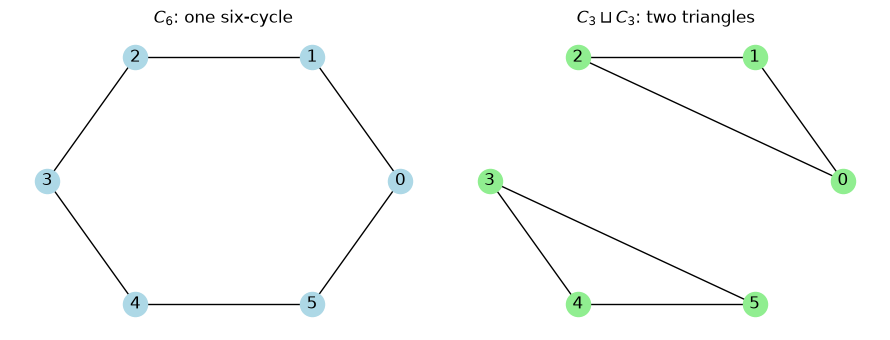

round 0: same colour histogram = True; C6=[0, 0, 0, 0, 0, 0], two triangles=[0, 0, 0, 0, 0, 0]
round 1: same colour histogram = True; C6=[0, 0, 0, 0, 0, 0], two triangles=[0, 0, 0, 0, 0, 0]
round 2: same colour histogram = True; C6=[0, 0, 0, 0, 0, 0], two triangles=[0, 0, 0, 0, 0, 0]
round 3: same colour histogram = True; C6=[0, 0, 0, 0, 0, 0], two triangles=[0, 0, 0, 0, 0, 0]
round 4: same colour histogram = True; C6=[0, 0, 0, 0, 0, 0], two triangles=[0, 0, 0, 0, 0, 0]


In [6]:
C6 = nx.cycle_graph(6)
two_triangles = nx.disjoint_union(nx.cycle_graph(3), nx.cycle_graph(3))

fig, axes = plt.subplots(1, 2, figsize=(9, 3.5))
nx.draw_circular(C6, ax=axes[0], with_labels=True, node_color="lightblue")
axes[0].set_title("$C_6$: one six-cycle")
nx.draw_circular(two_triangles, ax=axes[1], with_labels=True, node_color="lightgreen")
axes[1].set_title("$C_3 \\sqcup C_3$: two triangles")
plt.tight_layout()
plt.show()

for row in joint_wl_trace(C6, two_triangles, rounds=4):
    t, hist1, hist2, same = row
    print(f"round {t}: same colour histogram = {same}; "
          f"C6={hist1}, two triangles={hist2}")

## 8. What the WL result says about message-passing GNNs

Under the usual assumptions—shared message/update functions and permutation-invariant neighbour aggregation—standard message-passing GNNs are **no more discriminative than 1-WL**. If two nodes begin with the same features and 1-WL cannot separate their neighbourhoods, a standard message-passing GNN cannot separate their states merely by stacking more such layers. With invariant graph readout, this also limits graph-level discrimination.

The slogan “MP-GNNs are bounded by 1-WL” needs two qualifications:

1. It is an **upper bound**, not a claim that every GNN reaches the full power of 1-WL. Some aggregators are weaker; for example, mean aggregation can map different multisets to the same value.
2. Certain carefully designed message-passing models, such as GIN-style architectures under suitable assumptions, can match 1-WL's distinguishing power.

### Proof intuition

If two nodes have the same current representation and identical multisets of neighbour representations, an invariant aggregator returns the same aggregate. A shared update function therefore produces the same next representation. Induction gives the correspondence with successive 1-WL refinement rounds.

$$
\text{neighbour multiset}
\;\xrightarrow{\text{invariant aggregation}}\;
\text{aggregate}
\;\xrightarrow{\text{shared update}}\;
\text{new state}.
$$

This is not a theorem that 1-WL completely solves graph isomorphism. The implication is one-way:

$$
\text{1-WL distinguishes }G,H\ \Longrightarrow\ G\not\cong H,
$$

but in general,

$$
G\not\cong H\ \not\Longrightarrow\ \text{1-WL distinguishes }G,H.
$$

## 9. A contrasting pair that 1-WL separates immediately

A star $K_{1,4}$ and a path $P_5$ have different degree sequences. With uniform initial colours, their first refinement round separates the hub and leaves of the star from the degree pattern in the path.

Star degree sequence: [1, 1, 1, 1, 4]
Path degree sequence: [1, 1, 2, 2, 2]


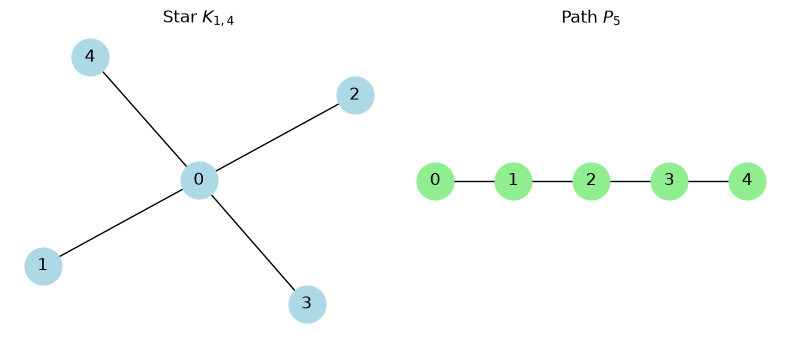

In [7]:
star = nx.star_graph(4)
path = nx.path_graph(5)
print("Star degree sequence:", sorted(dict(star.degree()).values()))
print("Path degree sequence:", sorted(dict(path.degree()).values()))

fig, axes = plt.subplots(1, 2, figsize=(8, 3.5))
nx.draw_networkx(star, pos=nx.spring_layout(star, seed=3), ax=axes[0],
                 node_color="lightblue", node_size=700)
axes[0].set_title("Star $K_{1,4}$")
nx.draw_networkx(path, pos={i: (i, 0) for i in path.nodes()}, ax=axes[1],
                 node_color="lightgreen", node_size=700)
axes[1].set_title("Path $P_5$")
for ax in axes: ax.axis("off")
plt.tight_layout()
plt.show()

## 10. PyTorch Geometric preview

PyG's `MessagePassing` class makes this pattern explicit through `propagate`, `message`, and an aggregation rule. For an undirected graph, each edge is usually stored in both directions so each endpoint can receive a message from the other.

In [8]:
try:
    from torch_geometric.data import Data
    from torch_geometric.nn import MessagePassing

    class SumNeighborLayer(MessagePassing):
        def __init__(self):
            super().__init__(aggr="add")

        def forward(self, x, edge_index):
            return self.propagate(edge_index, x=x)

        def message(self, x_j):
            # x_j is the feature of the source node for each message.
            return x_j

    pairs = []
    for u, v in G.edges():
        i, j = node_to_idx[u], node_to_idx[v]
        pairs.extend([(i, j), (j, i)])
    edge_index = torch.tensor(pairs, dtype=torch.long).t().contiguous()
    data = Data(x=X, edge_index=edge_index)

    pyg_layer = SumNeighborLayer()
    print(data)
    print("Neighbour sums from PyG:")
    print(pyg_layer(data.x, data.edge_index))
except ImportError as exc:
    print("PyTorch Geometric is unavailable in this kernel:", exc)

/opt/anaconda3/envs/gdl/lib/python3.12/site-packages/tqdm/auto.py:21: TqdmWarning: IProgress not found. Please update jupyter and ipywidgets. See https://ipywidgets.readthedocs.io/en/stable/user_install.html
  from .autonotebook import tqdm as notebook_tqdm
/opt/anaconda3/envs/gdl/lib/python3.12/site-packages/torch/jit/_script.py:1491: FutureWarning: `torch.jit.script` is deprecated. Please switch to `torch.compile` or `torch.export`.
  warnings.warn(


Data(x=[5, 1], edge_index=[2, 10])
Neighbour sums from PyG:
tensor([[ 2.5000],
        [ 1.5000],
        [ 6.0000],
        [-0.5000],
        [ 3.0000]])


## 11. Examples, non-examples, and exercises

**Examples**
- GCN, GraphSAGE, and GAT layers all use neighbourhood information, though their message/aggregation rules differ.
- A graph classifier can combine message passing with sum, mean, or max readout.
- A GNN layer shared across nodes respects relabeling symmetry when its aggregation is permutation-invariant.

**Non-examples / caveats**
- An MLP applied independently to node features without using edges is not message passing.
- An order-sensitive neighbour concatenation is not automatically permutation-invariant.
- Standard message-passing GNNs do not distinguish every non-isomorphic graph.
- One layer only aggregates one-hop information; deeper layers expand the receptive field.

**Exercises**
1. Compute the neighbour sums for the five-node graph by hand.
2. Replace sum aggregation with mean. Which nodes change and why?
3. Add self-loops. How does the update change?
4. Explain why aggregation must ignore arbitrary neighbour ordering.
5. Run 1-WL on a path \(P_5\) and a star \(K_{1,4}\). What is distinguished at the first round?
6. Explain why \(C_6\) and \(C_3\sqcup C_3\) are not separated by 1-WL.
7. Distinguish graph isomorphism, the 1-WL test, and GNN expressive power.

## Summary

Message-passing GNNs repeatedly exchange messages along edges, aggregate neighbour information invariantly, and update node states with shared functions. The 1-WL test gives a useful theoretical benchmark: standard message-passing GNNs are bounded by 1-WL, and some architectures can attain its power, but 1-WL itself fails on some non-isomorphic graphs.

## References

1. M. M. Bronstein, J. Bruna, T. Cohen, and P. Veličković, “Geometric Deep Learning: Grids, Groups, Graphs, Geodesics, and Gauges,” arXiv:2104.13478, especially §4.1. https://arxiv.org/abs/2104.13478
2. W. L. Hamilton, *Graph Representation Learning*, Synthesis Lectures on Artificial Intelligence and Machine Learning, especially Chapter 5 “The Graph Neural Network Model” and Chapter 7 “Theoretical Motivations.” https://www.cs.mcgill.ca/~wlh/grl_book/
3. J. Gilmer et al., “Neural Message Passing for Quantum Chemistry,” ICML (2017). https://arxiv.org/abs/1704.01212
4. K. Xu et al., “How Powerful are Graph Neural Networks?” ICLR (2019). https://arxiv.org/abs/1810.00826
5. C. Morris et al., “Weisfeiler and Leman Go Neural: Higher-order Graph Neural Networks,” AAAI (2019). https://arxiv.org/abs/1810.02244

The proto-book provides the geometric/message-passing framing; Hamilton provides a fuller graph-representation-learning treatment. The discussion of 1-WL is expanded here to make the limitations and the one-way isomorphism implication explicit.